# Why?

The very first question which comes in the mind is, **why do we need to encode numeric data to categorical data?**

The ans is, sometimes we get better result in categorical features. For e.g: If we're working with the dataset of Playstore and we've a column named **No.of downloads**, it's value would be like, 250, 28, 49, 2500, 9000 for not so popular apps and for popular apps, it would be, 1522548, 9821145 etc.

Here we may not get better results and so we can convert this data into `bins` like 10+, 100+, 1k+, 10k+, 100k+, 1M+ etc.

**There're two methods to encode numeric data. They're,**
1) Discretization(Binning) and
2) Binarization

**What is Discretization?**
* Discretization is the process of transformimg continuous variables into discrete variables by creating bins of equal intervals.
* Discretization is also known as `Binning`.
* For eg, we've `Age` column and the data are 8, 9, 15, 12, 25, 41, 32, 35, 16, 55, 51, 43, 21, 36, 57, 56, 36, 32, 25, 45.
* Here, we can create bins like, 0-10, 10-20, 20-30, 30-40, 40-50.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('00 Titanic.csv', usecols = ['Age', 'Fare', 'Survived'])

In [3]:
df.sample(8)

,Survived,Age,Fare
832,0,NaN,7.2292
883,0,28.00,10.5000
152,0,55.50,8.0500
818,0,43.00,6.4500
803,1,0.42,8.5167
287,0,22.00,7.8958
688,0,18.00,7.7958
370,1,25.00,55.4417


In [4]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [5]:
df.dropna(inplace = True)

In [6]:
df.shape

(714, 3)

# Train/Test split.

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
x = df[['Age', 'Fare']]
y = df.drop(x, axis = 'columns')

In [9]:
y.sample(5)

,Survived
575,0
116,0
463,0
867,0
703,0


In [10]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

# Before binning.

In [11]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()

In [12]:
dt.fit(x_train, y_train)

DecisionTreeClassifier()

In [13]:
pred_b4 = dt.predict(x_test)

In [14]:
from sklearn.metrics import accuracy_score

In [15]:
acc_b4 = accuracy_score(pred_b4, y_test)
acc_b4

0.5944055944055944

In [16]:
# Cross validation

from sklearn.model_selection import cross_val_score

In [17]:
cross_val_score(estimator = dt, X = x, y = y, cv = 10, scoring = 'accuracy').mean()

0.6358763693270735

# After Bining

In [1]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import KBinsDiscretizer

In [19]:
kbin = KBinsDiscretizer(n_bins = 10, strategy = 'quantile', encode = 'ordinal')


# strategy = uniform/ quantile/ kmeans. Bydefault quantile
# encode = ordinal or one-hot.

In [20]:
trans = [
    ('kbin_age', kbin, [0, 1])
]

In [21]:
ct = ColumnTransformer(transformers = trans, remainder = 'passthrough')

In [22]:
x_train_trans = ct.fit_transform(x_train)
x_test_trans = ct.transform(x_test)

In [23]:
x_train_trans

array([[1., 5.],
       [3., 0.],
       [9., 7.],
       ...,
       [6., 9.],
       [5., 0.],
       [0., 6.]])

In [24]:
print(ct.named_transformers_)
print()

print(ct.named_transformers_['kbin_age'])
print()

print(ct.named_transformers_['kbin_age'].n_bins_)    # n_bins_ shoes the no.of bins created.

{'kbin_age': KBinsDiscretizer(encode='ordinal', n_bins=10)}

KBinsDiscretizer(encode='ordinal', n_bins=10)

[10 10]


In [25]:
print(ct.named_transformers_['kbin_age'].bin_edges_)    # bin_edges_ shows the interval of each bins created.

[array([ 0.42, 14.5 , 19.  , 22.  , 25.  , 29.  , 32.  , 36.  , 42.  ,
        50.  , 74.  ])
 array([  0.    ,   7.75  ,   7.8958,   8.6625,  12.65  ,  15.55  ,
         26.    ,  29.    ,  46.9   ,  79.65  , 512.3292])         ]


In [26]:
data = {
    'Age':x_train['Age'],
    'Age_trans': x_train_trans[:, 0],
    'Fare': x_train['Fare'],
    'Fare_trans': x_train_trans[:, 1]
}

In [27]:
df2 = pd.DataFrame(data)

In [28]:
df2

,Age,Age_trans,Fare,Fare_trans
651,18.0,1.0,23.0000,5.0
212,22.0,3.0,7.2500,0.0
487,58.0,9.0,29.7000,7.0
813,6.0,0.0,31.2750,7.0
853,16.0,1.0,39.4000,7.0
...,...,...,...,...
704,26.0,4.0,7.8542,1.0
555,62.0,9.0,26.5500,6.0
269,35.0,6.0,135.6333,9.0
365,30.0,5.0,7.2500,0.0


In [29]:
df2['Age_label'] = pd.cut(x = x_train['Age'], bins = ct.named_transformers_['kbin_age'].bin_edges_[0].tolist())
df2['Fare_label'] = pd.cut(x = x_train['Fare'], bins = ct.named_transformers_['kbin_age'].bin_edges_[1].tolist())

In [30]:
df2

,Age,Age_trans,Fare,Fare_trans,Age_label,Fare_label
651,18.0,1.0,23.0000,5.0,"(14.5, 19.0]","(15.55, 26.0]"
212,22.0,3.0,7.2500,0.0,"(19.0, 22.0]","(0.0, 7.75]"
487,58.0,9.0,29.7000,7.0,"(50.0, 74.0]","(29.0, 46.9]"
813,6.0,0.0,31.2750,7.0,"(0.42, 14.5]","(29.0, 46.9]"
853,16.0,1.0,39.4000,7.0,"(14.5, 19.0]","(29.0, 46.9]"
...,...,...,...,...,...,...
704,26.0,4.0,7.8542,1.0,"(25.0, 29.0]","(7.75, 7.896]"
555,62.0,9.0,26.5500,6.0,"(50.0, 74.0]","(26.0, 29.0]"
269,35.0,6.0,135.6333,9.0,"(32.0, 36.0]","(79.65, 512.329]"
365,30.0,5.0,7.2500,0.0,"(29.0, 32.0]","(0.0, 7.75]"


# Note: The numbers in the transformed columns indicated on which bin it falls.

In [31]:
ct.named_transformers_['kbin_age'].bin_edges_[0].tolist()

[0.42, 14.5, 19.0, 22.0, 25.0, 29.0, 32.0, 36.0, 42.0, 50.0, 74.0]

In [32]:
df2.isnull().sum()

Age           0
Age_trans     0
Fare          0
Fare_trans    0
Age_label     1
Fare_label    6
dtype: int64

In [33]:
df2.dropna(inplace = True)

In [34]:
dt2 = DecisionTreeClassifier()

dt2.fit(x_train_trans, y_train)

DecisionTreeClassifier()

In [35]:
pred_after = dt2.predict(x_test_trans)

In [36]:
acc_after = accuracy_score(pred_after, y_test)
acc_after

0.6713286713286714

In [37]:
import matplotlib.pyplot as plt

In [38]:
def discretize(bins,strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    
    trf = ColumnTransformer([
        ('first',kbin_age,[0]),
        ('second',kbin_fare,[1])
    ])
    
    X_trf = trf.fit_transform(x)
    print(np.mean(cross_val_score(DecisionTreeClassifier(),x,y,cv=10,scoring='accuracy')))
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(x['Age'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(x_train_trans[:,0],color='red')
    plt.title("After")

    plt.show()
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(x['Fare'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(x_train_trans[:,1],color='red')
    plt.title("Fare")

    plt.show()
    print(trf.named_transformers_.first.bin_edges_)

0.6289319248826291


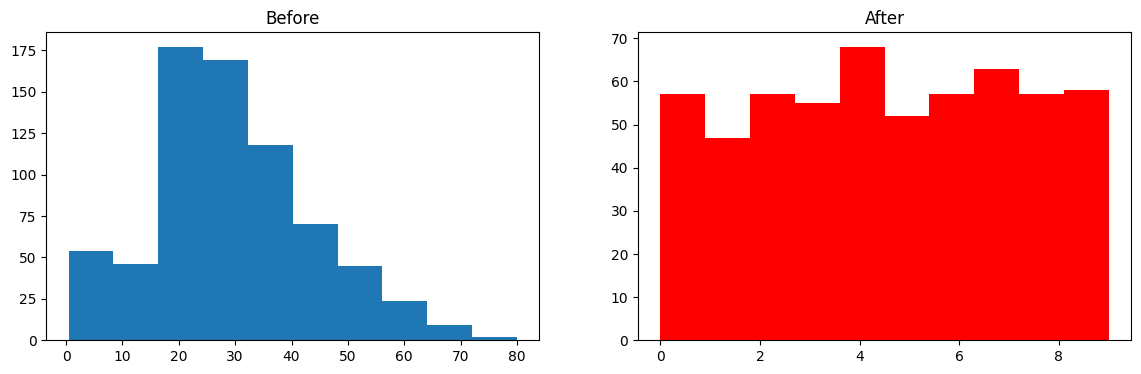

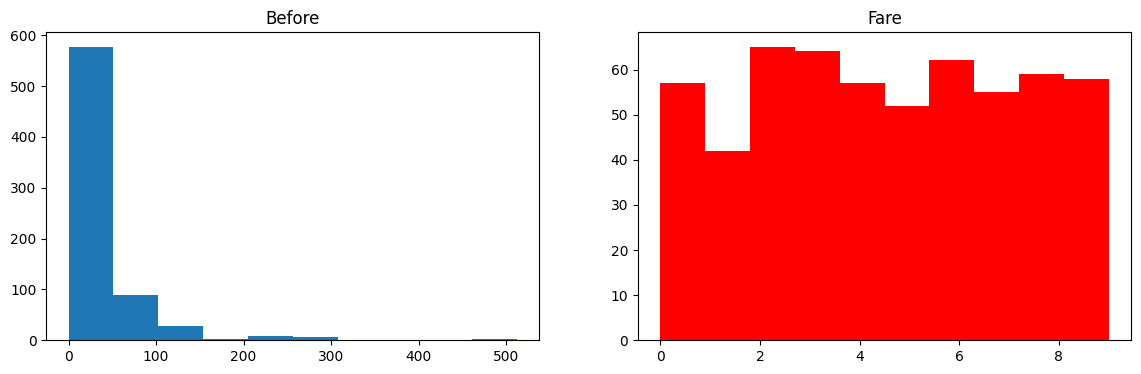

[array([ 0.42      ,  5.72533333, 11.03066667, 16.336     , 21.64133333,
        26.94666667, 32.252     , 37.55733333, 42.86266667, 48.168     ,
        53.47333333, 58.77866667, 64.084     , 69.38933333, 74.69466667,
        80.        ])                                                   ]


In [40]:
discretize(bins = 15, strategy = 'uniform')